# BRENDA kinetics — human enzyme review protocol

This first protocol reviews one source and one enzyme-organism cohort. It
preserves the complete relational contract, including accepted nonnumeric
measurements and empty site tables. **Human enzyme does not mean human serum.**
Sample species, matrix and in-vitro mode remain undocumented unless explicitly
curated. This notebook does not perform MEROPS matching or cross-family enrichment.

The physiological pH/temperature references below are display markers only.
Unusual reported temperatures remain visible in the audit table; spacing beyond
60°C is compressed when needed, while tick labels remain in degrees Celsius.
Acceptance bounds are deliberately disabled for the first review; no missing
conditions are filled with reference values.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "assets/tools/proteolysis_data_manager").is_dir())
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
from proteolysis_data_manager.integration.kinetics.reader import load_kinetics_data
from proteolysis_data_manager.analysis.kinetics.overview import (
    table_inventory, missingness, species_coverage, parameter_summary,
    formatted_table, plot_parameters, plot_conditions,
)
DATA_ROOT = ROOT / "data/kinetics_datasets"
SERIES = ROOT / "assets/experiments/analysis/09_26/20_serum_proteolysis_calibration_max/notebooks/0_data_analysis_kinetics"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .12})
def table(frame, limit=30):
    if len(frame) > limit:
        print(f"Preview: {limit} of {len(frame)} rows")
    display(HTML(formatted_table(frame, limit)))
def figure(fig):
    plt.show()
    plt.close(fig)

In [2]:
dataset = load_kinetics_data(DATA_ROOT)
CONFIG = json.loads((SERIES / "protocols/protocol_config.json").read_text())
WRITE_EXPORTS = True
from proteolysis_data_manager.protocols.kinetics.filtering import evaluate_protocol, export_protocol
rows = evaluate_protocol(dataset, CONFIG)
retained = rows.loc[rows.accepted].copy()
table(pd.DataFrame([{"condition_key": CONFIG["condition_key"], "enzyme_species": CONFIG["enzyme_species"],
    "source_measurements": len(rows), "retained_measurements": len(retained),
    "accepted_numeric": int(retained.value_numeric.notna().sum()),
    "accepted_non_numeric": int(retained.value_numeric.isna().sum()),
    "positive_numeric_for_model_review": int(retained.numeric_model_eligible.sum())}]))
table(pd.DataFrame([{"parameter": field, "bounds": bounds, "enabled": bounds is not None,
    "missing_policy": CONFIG["missing_condition_policy"]} for field, bounds in CONFIG["acceptance_bounds"].items()]))

condition_key,enzyme_species,source_measurements,retained_measurements,accepted_numeric,accepted_non_numeric,positive_numeric_for_model_review
human_enzyme,Homo sapiens,26697,8398,8180,218,8180


parameter,bounds,enabled,missing_policy
ph,None,False,retain
temperature_c,None,False,retain


## Input documentation and descriptive distributions

Neither substrate length, parameter value, missing sequence nor absent cleavage
annotation is an acceptance gate. Numerical modeling eligibility is reported
separately; it does not remove incomplete measurements from the exported bundle.
The substrate-length table may be empty because BRENDA names are not resolved
to sequences at this stage.

parameter,unit,measurements,numeric,non_numeric,min,median,max
kcat,s^-1,10639,10378,261,5.83e-10,4.7,9.1e+05
kcat_km,M^-1 s^-1,2974,2951,23,0.00065,4.7e+04,2.5e+10
km,M,13084,12576,508,2.42e-10,7.2e-05,1.3


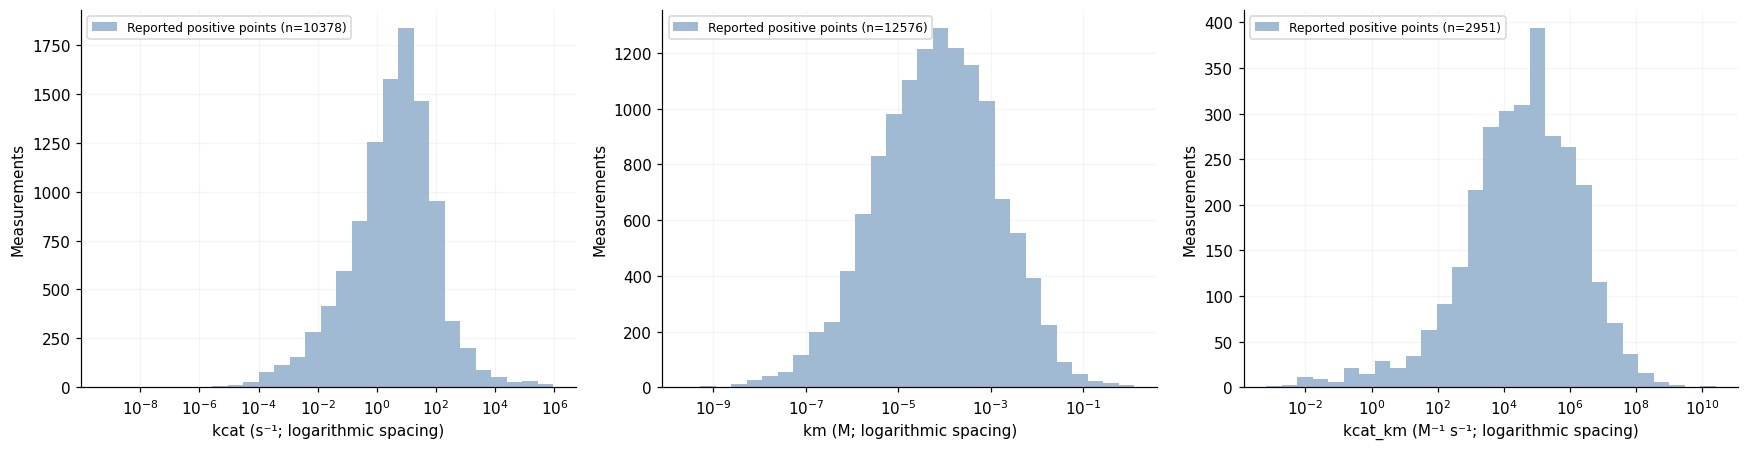

field,missing_input,missing_retained
sequence,26697,8398
chirality,26697,8398
topology,26697,8398
species,26697,8398
matrix,26697,8398
in_vivo_in_vitro,26697,8398
ph,10125,3050
temperature_c,11025,3394
sd,26697,8398
ci_lower,26697,8398


reported_substrate_lengths,missing_lengths
0,26697


In [3]:
table(parameter_summary(rows))
figure(plot_parameters(rows))
fields = ["sequence", "chirality", "topology", "species", "matrix", "in_vivo_in_vitro", "ph", "temperature_c", "sd", "ci_lower", "ci_upper"]
table(pd.DataFrame([{"field": field, "missing_input": int(rows[field].isna().sum()),
                    "missing_retained": int(retained[field].isna().sum())} for field in fields]))
lengths = rows.sequence_length.dropna()
table(pd.DataFrame([{"reported_substrate_lengths": len(lengths), "missing_lengths": int(rows.sequence_length.isna().sum())}]))
if len(lengths):
    fig, ax = plt.subplots(figsize=(8, 3.5)); ax.hist(lengths, bins=25, color="#4477AA")
    ax.set(xlabel="Reported substrate length (residues)", ylabel="Measurements"); figure(fig)

## Acceptance, documentation and future scaling parameters

The cohort accepts source contexts whose protein links all identify the target
enzyme organism. Mixed-species or undocumented protein links are not attributed
to the target. Several human protein links remain unresolved enzyme associations.

pH/T thresholds can be enabled in `CONFIG`; explicit missing-value policy applies
only to enabled gates. There is one condition plot, showing reported values and
display references. No assumed/effective duplicates are generated.

Matrix fraction and concentrations are not acceptance gates or automatic rate
multipliers. Dilution remains in the schema; concentrations and other descriptive
details remain in raw/comments pending focused curation and a reviewed extension.

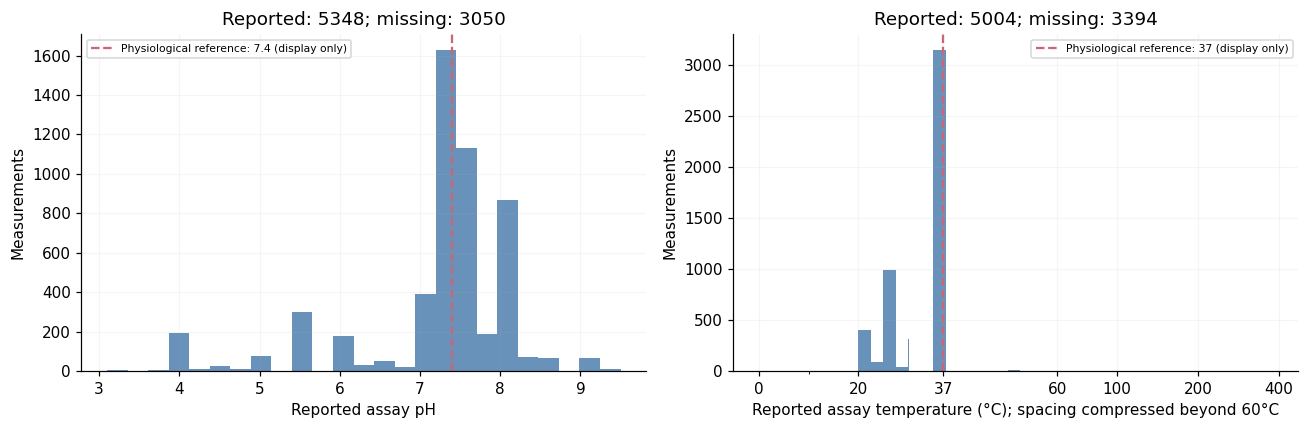

temperature_c,conditions_raw,source_record_id
378,"pH 4.0, 378°C, mutant enzyme E77A","[{'source': 'brenda', 'id': 'data/3.4.14.9/turnover_number/26'}]"


reason,measurements
enzyme_species_not_uniquely_target,18299


Preview: 15 of 18299 rows


measurement_id,enzyme_species,parameter_type,exclusion_reasons
brenda:measurement:d13c4077cc4ec3f284fe3d7f,[Bos taurus],kcat,[enzyme_species_not_uniquely_target]
brenda:measurement:caf2d9401bbd6a0a114a4cca,[Thermotoga maritima],kcat,[enzyme_species_not_uniquely_target]
brenda:measurement:57c8b8bc230725a5a6cfec02,[Thermotoga maritima],kcat,[enzyme_species_not_uniquely_target]
brenda:measurement:ad30034b09ea42e45959ecce,[Thermotoga maritima],kcat,[enzyme_species_not_uniquely_target]
brenda:measurement:97667c2fb5b92649d8a2b4a1,[Thermotoga maritima],kcat,[enzyme_species_not_uniquely_target]
brenda:measurement:75a13e2685d17d62235bbec2,[Thermotoga maritima],kcat,[enzyme_species_not_uniquely_target]
brenda:measurement:edcee131564d899a9ee7ea23,[Thermotoga maritima],kcat,[enzyme_species_not_uniquely_target]
brenda:measurement:b3866241bd03dbbbc40604fa,[Acanthamoeba castellanii],kcat,[enzyme_species_not_uniquely_target]
brenda:measurement:eebbcee0dc4207fdcadde3eb,[Acanthamoeba castellanii],kcat,[enzyme_species_not_uniquely_target]
brenda:measurement:0194657229e82b34c8bba8f7,[Acanthamoeba castellanii],kcat,[enzyme_species_not_uniquely_target]


accepted_human_enzyme_records,explicitly_documented_human_serum_records,matrix_not_curated,accepted_non_numeric_preserved
8398,0,8398,218


In [4]:
figure(plot_conditions(retained, CONFIG["references"], CONFIG["acceptance_bounds"]))
table(retained.loc[retained.temperature_c.gt(100), ["temperature_c", "conditions_raw", "source_record_id"]], 20)
reasons = rows.loc[~rows.accepted, "exclusion_reasons"].explode().value_counts().rename_axis("reason").reset_index(name="measurements")
table(reasons)
table(rows.loc[~rows.accepted, ["measurement_id", "enzyme_species", "parameter_type", "exclusion_reasons"]], 15)
documented_serum = retained.species.eq("human") & retained.matrix.eq("serum")
table(pd.DataFrame([{"accepted_human_enzyme_records": len(retained),
    "explicitly_documented_human_serum_records": int(documented_serum.sum()),
    "matrix_not_curated": int(retained.matrix.isna().sum()),
    "accepted_non_numeric_preserved": int(retained.value_numeric.isna().sum())}]))

## Before/after and uncertainty

The shared plots compare positive numerical values in the same units. The
counts below include all labels, including ranges/bounds and unresolved values.
No synthetic CI is added.

**TODO — downstream uncertainty model:** design and validate an estimator or
tolerance policy in later analysis. Missing CI stays null in this protocol.

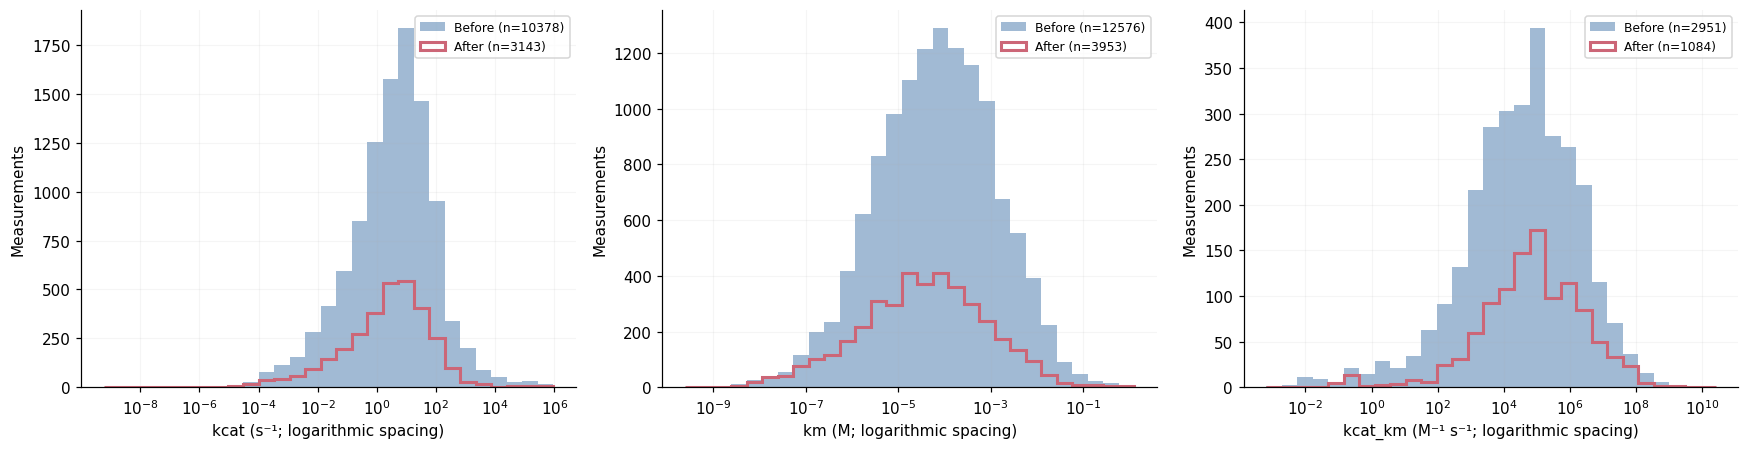

parameter,unit,measurements,numeric,non_numeric,min,median,max
kcat,s^-1,3221,3143,78,1.8e-09,3.3,3.96e+05
kcat_km,M^-1 s^-1,1096,1084,12,0.104,7.6e+04,1.011e+09
km,M,4081,3953,128,7e-10,4e-05,0.933


parameter_type,value_relation,before,after
kcat,eq,10378,3143
kcat,range,121,39
kcat,unknown,140,39
kcat_km,eq,2951,1084
kcat_km,range,4,3
kcat_km,unknown,19,9
km,eq,12576,3953
km,range,83,15
km,unknown,425,113


In [5]:
figure(plot_parameters(rows, retained))
table(parameter_summary(retained))
labels_before = rows.groupby(["parameter_type", "value_relation"]).size().rename("before")
labels_after = retained.groupby(["parameter_type", "value_relation"]).size().rename("after")
table(pd.concat([labels_before, labels_after], axis=1).fillna(0).reset_index())
assert len(rows) == len(retained) + int((~rows.accepted).sum())
assert len(retained) == retained.value_numeric.notna().sum() + retained.value_numeric.isna().sum()

## Export a closed relational bundle

The export retains all accepted measurements and their experiment, substrate,
enzyme and site relations. It writes eight Parquet tables with the same schema
as normalized data, plus a centralized manifest. No final multi-source aggregate
is generated before this first protocol is reviewed.

In [6]:
if WRITE_EXPORTS:
    reviewed, manifest = export_protocol(dataset, rows, DATA_ROOT, CONFIG)
    reloaded = load_kinetics_data(DATA_ROOT, condition=CONFIG["condition_key"])
    assert len(reloaded["kinetic_measurements"]) == len(retained)
    assert reloaded["kinetic_measurements"].value_numeric.isna().sum() == retained.value_numeric.isna().sum()
    table(table_inventory(reloaded))
    print("Output:", DATA_ROOT / "processed" / CONFIG["condition_key"] / "sources/brenda")
else:
    print("Template: exports disabled. Copy and review CONFIG before enabling exports.")

table,rows,columns
enzymes,1224,9
substrates,2620,12
experiments,8398,14
experiment_enzymes_relation,8402,3
experiment_substrates_relation,8398,2
kinetic_measurements,8398,13
cleavage_sites,0,13
measurement_cleavage_sites_relation,0,2


Output: /Users/max/Documents/repositories/pep-compass/data/kinetics_datasets/processed/human_enzyme/sources/brenda
